# 04 · XAI y evaluación cross-domain
**Responsable: Felipe Aguilar.** Se recalculan resultados reales de los CSV entregados; no se entrena ni se ajustan umbrales sobre test.

Este notebook se puede ejecutar sin fotos para consolidar las predicciones. Grad-CAM, Guatemala y nuevas latencias requieren imágenes y checkpoints: su ausencia se registra como pendiente, nunca como un resultado. Consulte `docs/XAI_EVALUACION.md` para ejecutar esas etapas y defender los hallazgos.

**EfficientNet-B0:** el consolidador incorpora automáticamente sus resultados completos cuando existen bajo `reports/experiments/efficientnet/`. Su implementación y protocolo están en `docs/EFFICIENTNET.md`. El VAE se conserva. No confundir una implementación probada con un modelo ya entrenado en RDD2022.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd() if (Path.cwd() / 'src').is_dir() else Path.cwd().parent
assert (ROOT / 'src/evaluation/cross_domain.py').is_file(), 'Abra el notebook desde el repositorio'
sys.path.insert(0, str(ROOT))
from src.evaluation.cross_domain import run
OUT = ROOT / 'reports/xai_evaluation'
metrics, status = run(output=OUT)


experiment_id            split    n  precision   recall       f1   pr_auc  flagged_rate
     vae_base          test_id 4174   0.121638 1.000000 0.216893 0.108306      0.988740
     vae_base         test_ood 8161   0.031369 1.000000 0.060829 0.034880      1.000000
     vae_base test_perspective 2401   0.027716 0.968750 0.053890 0.024890      0.931695
     vae_base              val 4173   0.121756 0.996032 0.216987 0.101190      0.988018
 vae_patch512          test_id 4174   0.120230 0.998008 0.214607 0.105432      0.998323
 vae_patch512         test_ood 8161   0.031369 1.000000 0.060829 0.048360      1.000000
 vae_patch512 test_perspective 2401   0.030286 0.843750 0.058473 0.021554      0.742607
 vae_patch512              val 4173   0.120892 1.000000 0.215707 0.104474      0.999041


## Protocolo y lectura de las métricas
Se verifica `dataset_v1`, sus hashes, cobertura completa y etiquetas. Umbral fijo elegido por F1 en `val`; selección de clasificadores ResNet/EfficientNet por AP de `val`. `test_ood` es Noruega, `test_perspective` es China_Drone; ninguno representa Guatemala.

AP (`pr_auc`) es average precision de sklearn, no área trapezoidal. Contrastar con prevalencia. Recall alto con casi todas las imágenes positivas puede ser degenerado. ΔF1 = F1 interno − F1 externo: positivo significa caída, en unidades absolutas. Cambios de prevalencia afectan F1 y precisión; la caída sola no demuestra su causa visual.

,experiment_id,split,n,prevalence,precision,recall,f1,pr_auc,fpr,flagged_rate
0,vae_base,test_id,4174,0.1203,0.1216,1.0000,0.2169,0.1083,0.9872,0.9887
1,vae_base,test_ood,8161,0.0314,0.0314,1.0000,0.0608,0.0349,1.0000,1.0000
2,vae_base,test_perspective,2401,0.0267,0.0277,0.9688,0.0539,0.0249,0.9307,0.9317
3,vae_base,val,4173,0.1208,0.1218,0.9960,0.2170,0.1012,0.9869,0.9880
4,vae_patch512,test_id,4174,0.1203,0.1202,0.9980,0.2146,0.1054,0.9984,0.9983
5,vae_patch512,test_ood,8161,0.0314,0.0314,1.0000,0.0608,0.0484,1.0000,1.0000
6,vae_patch512,test_perspective,2401,0.0267,0.0303,0.8438,0.0585,0.0216,0.7398,0.7426
7,vae_patch512,val,4173,0.1208,0.1209,1.0000,0.2157,0.1045,0.9989,0.9990


,family,experiment_id,domain,f1_id,f1_external,delta_f1,recall_id,recall_external,delta_recall,prevalence_id,prevalence_external
0,vae,vae_base,test_ood,0.2169,0.0608,0.1561,1.000,1.0000,0.0000,0.1203,0.0314
1,vae,vae_base,test_perspective,0.2169,0.0539,0.1630,1.000,0.9688,0.0312,0.1203,0.0267
2,vae,vae_patch512,test_ood,0.2146,0.0608,0.1538,0.998,1.0000,-0.0020,0.1203,0.0314
3,vae,vae_patch512,test_perspective,0.2146,0.0585,0.1561,0.998,0.8438,0.1543,0.1203,0.0267


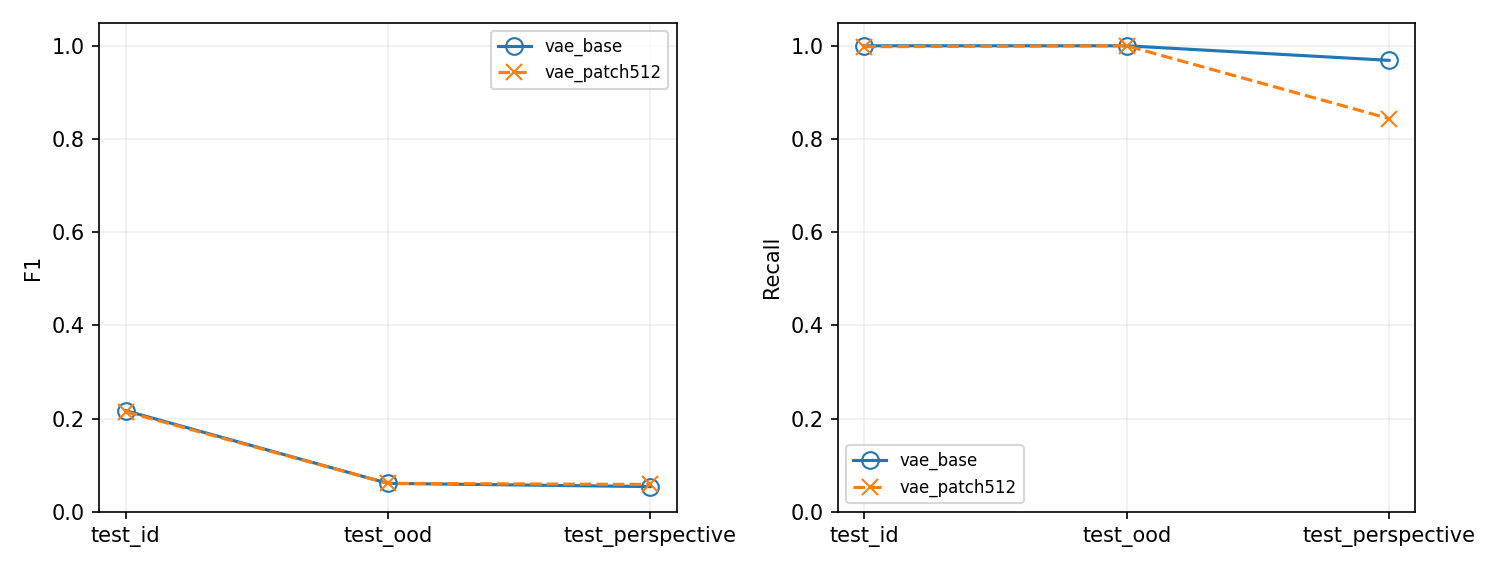

In [2]:
display(metrics[['experiment_id', 'split', 'n', 'prevalence', 'precision', 'recall', 'f1', 'pr_auc', 'fpr', 'flagged_rate']].round(4))
display(pd.read_csv(OUT / 'domain_shift.csv').round(4))
display(Image(filename=str(OUT / 'comparison.png')))


### vae_base

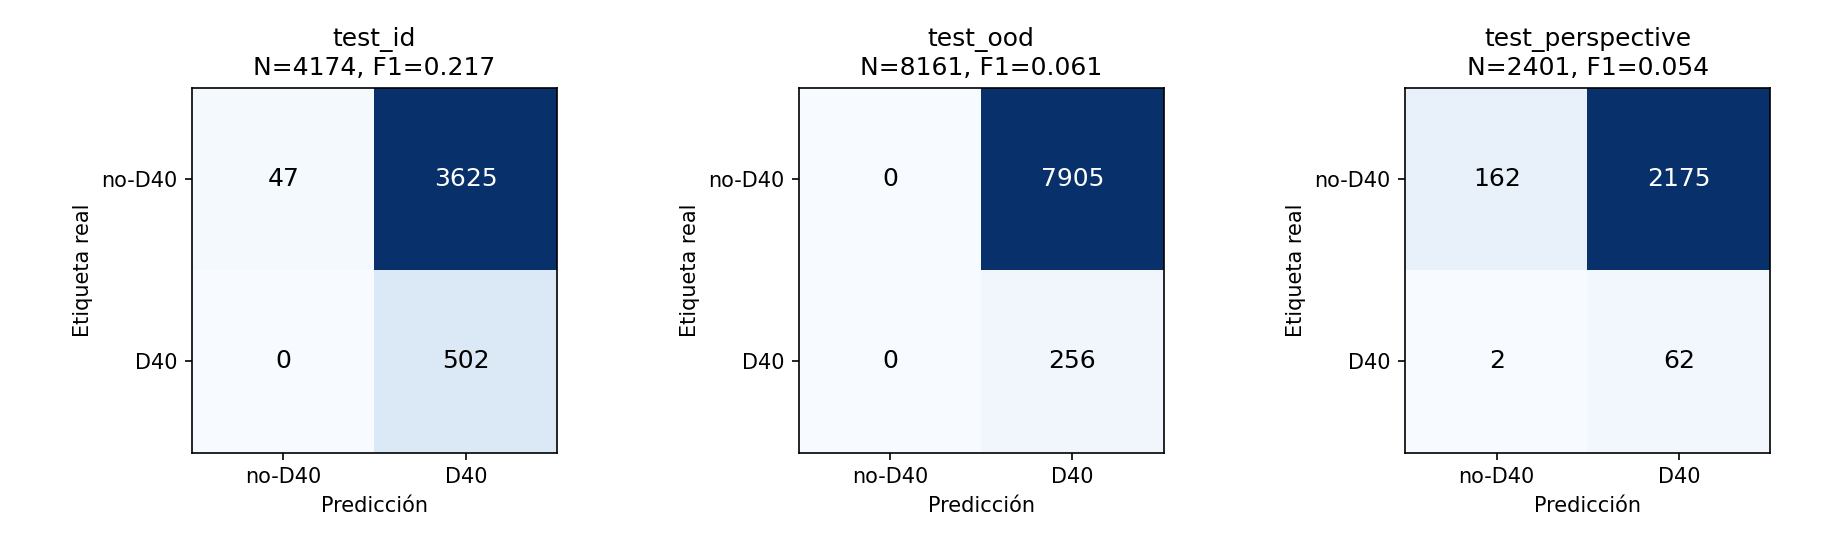

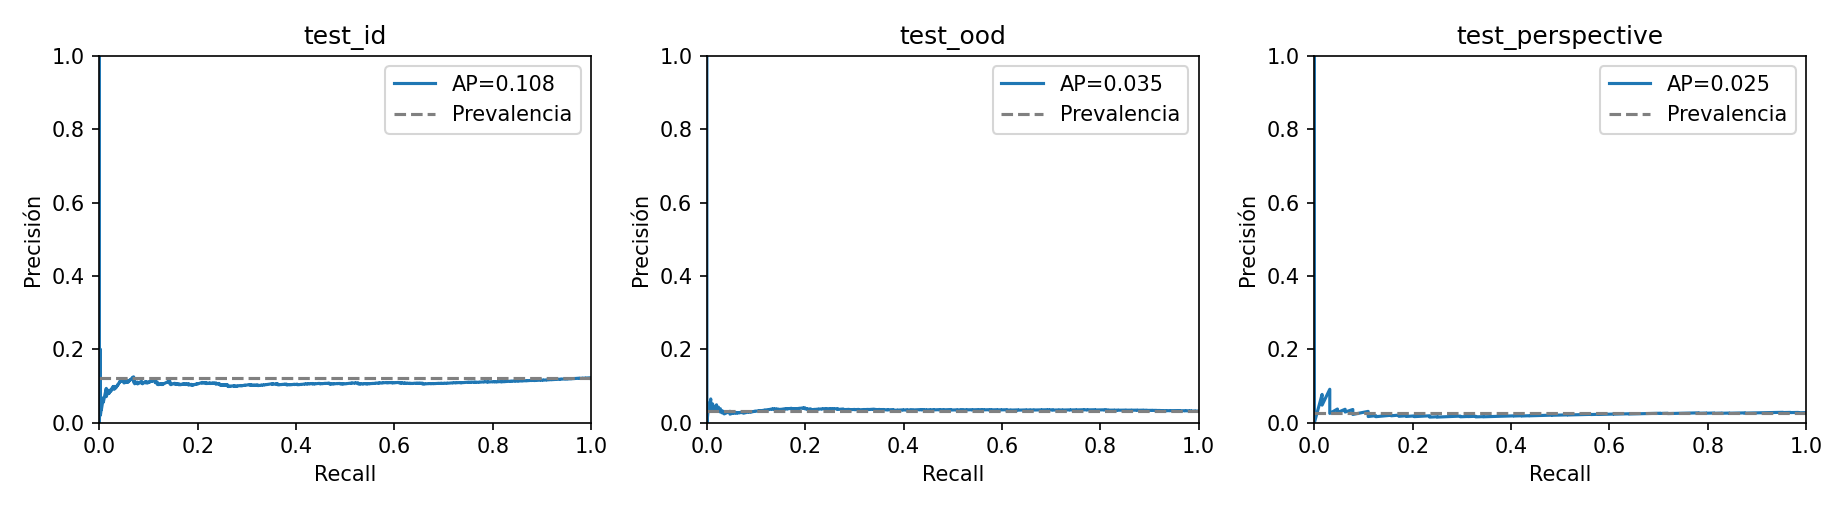

### vae_patch512

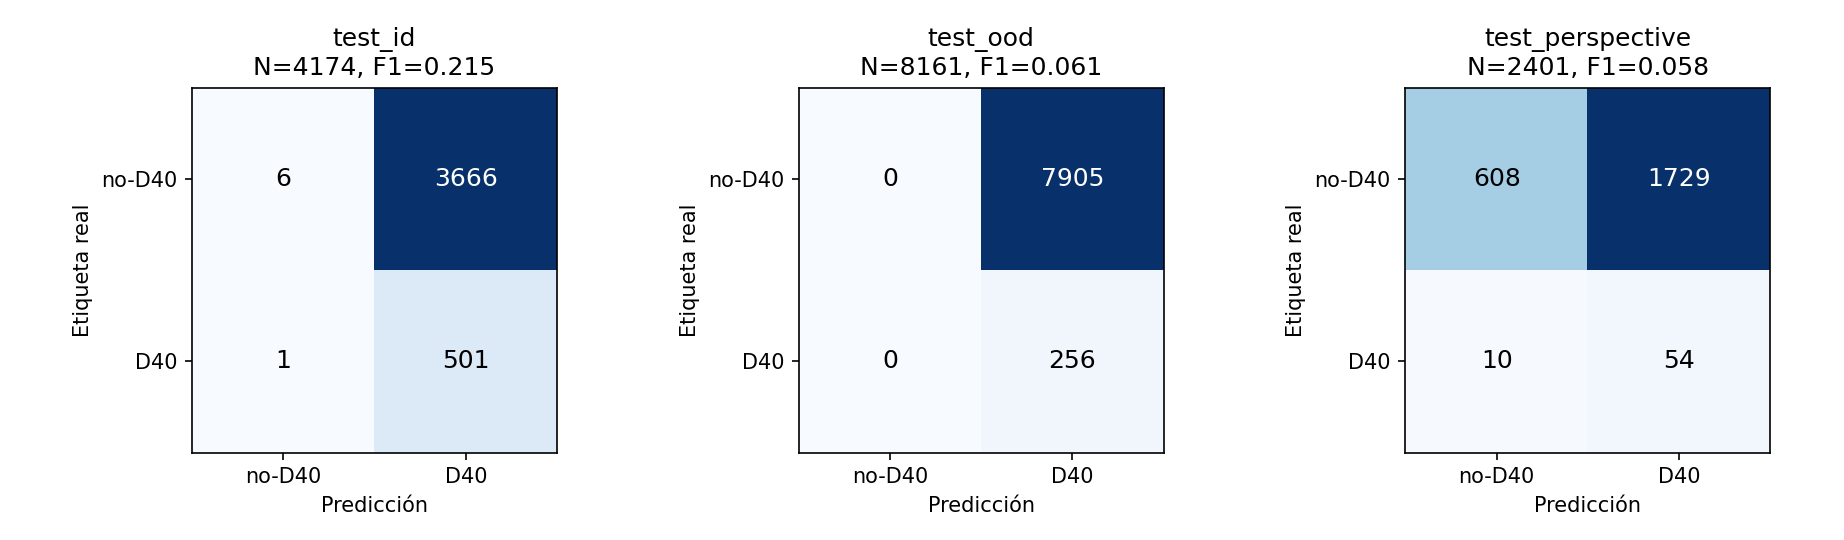

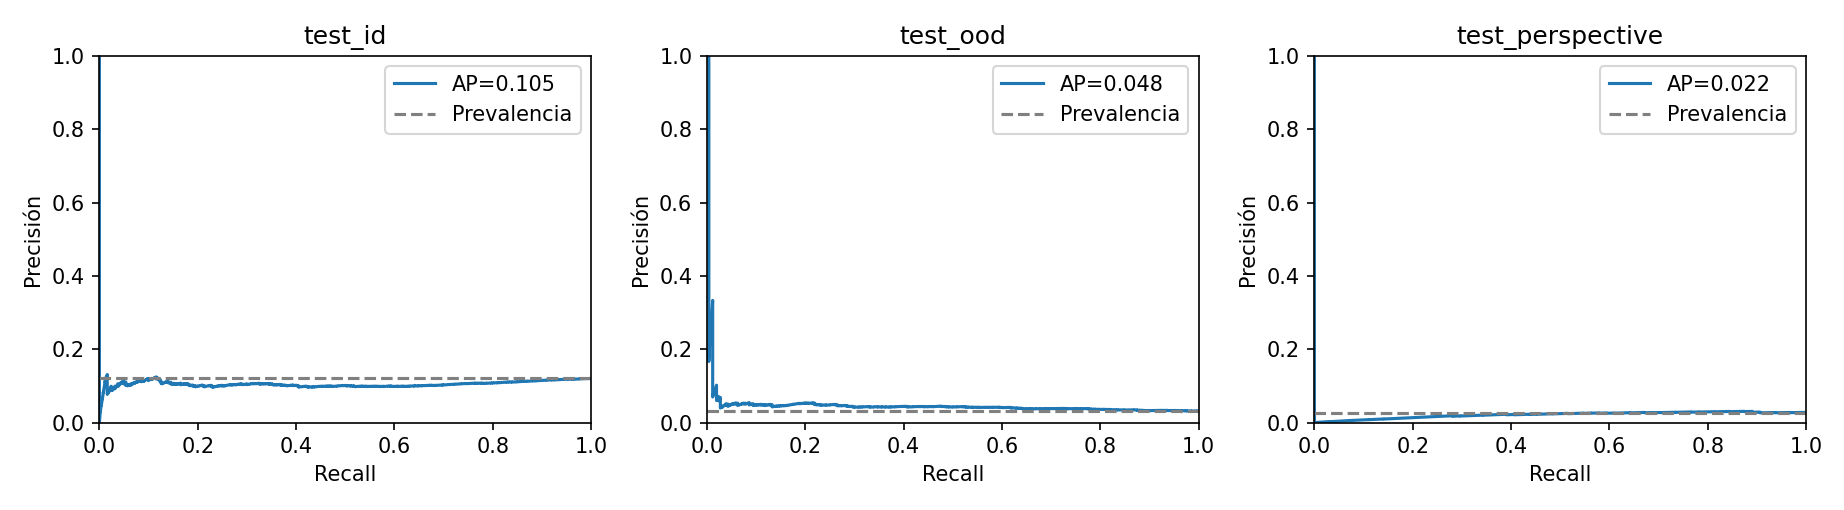

In [3]:
for experiment in metrics.experiment_id.unique():
    display(Markdown(f'### {experiment}'))
    display(Image(filename=str(OUT / experiment / 'confusion.png')))
    display(Image(filename=str(OUT / experiment / 'precision_recall.png')))


## Errores, selección de casos y auditoría
Los ejemplos son una muestra uniforme reproducible (semilla 42) de hasta tres TP/TN/FP/FN por dominio. Si un grupo está vacío se informa: no se cambia el umbral para fabricar ejemplos. `error_groups.json` desglosa otros daños y países; las clases de daño pueden solaparse. La explicación visual de sombras, textura o fondo requiere abrir la foto y el mapa, no inferirla de un CSV.

`archive_discrepancies.csv` conserva diferencias entre los números archivados y los recalculados. En `vae_base/val` hay un caso en el límite numérico del umbral: el CSV leído en float64 da 502 TP/2 FN frente a 503 TP/1 FN archivados. Se preservan scores y umbral, sin corregir a mano. Los tres tests de ambos VAE reproducen las matrices archivadas.

In [4]:
display(pd.read_csv(OUT / 'case_coverage.csv'))
display(pd.read_csv(OUT / 'cases.csv')[['experiment_id', 'sample_id', 'split', 'outcome', 'y_score', 'threshold']])
display(pd.read_csv(OUT / 'archive_discrepancies.csv'))
display(pd.read_csv(OUT / 'latency_reported.csv'))
print(json.dumps(status, indent=2, ensure_ascii=False))


,experiment_id,split,outcome,available
0,vae_base,test_id,TP,502
1,vae_base,test_id,TN,47
2,vae_base,test_id,FP,3625
3,vae_base,test_id,FN,0
4,vae_base,test_ood,TP,256
5,vae_base,test_ood,TN,0
6,vae_base,test_ood,FP,7905
7,vae_base,test_ood,FN,0
8,vae_base,test_perspective,TP,62
9,vae_base,test_perspective,TN,162


,experiment_id,sample_id,split,outcome,y_score,threshold
0,vae_base,Czech__Czech_003359,test_id,FP,0.044973,0.005552
1,vae_base,India__India_008722,test_id,FP,0.011082,0.005552
2,vae_base,Japan__Japan_011681,test_id,FP,0.049346,0.005552
3,vae_base,China_MotorBike__China_MotorBike_001136,test_id,TN,0.003179,0.005552
4,vae_base,China_MotorBike__China_MotorBike_001683,test_id,TN,0.003073,0.005552
5,vae_base,China_MotorBike__China_MotorBike_001105,test_id,TN,0.002308,0.005552
6,vae_base,India__India_009510,test_id,TP,0.041804,0.005552
7,vae_base,India__India_001156,test_id,TP,0.010061,0.005552
8,vae_base,Japan__Japan_000603,test_id,TP,0.032545,0.005552
9,vae_base,Norway__Norway_003585,test_ood,FP,0.031631,0.005552


,experiment_id,split,metric,archived,recomputed
0,vae_base,val,tp,503.000000,502.000000
1,vae_base,val,fn,1.000000,2.000000
2,vae_base,val,f1,0.217373,0.216987
3,vae_base,val,precision,0.121969,0.121756
4,vae_base,val,recall,0.998016,0.996032


,experiment_id,device,reported_median_ms,image_size,scope,comparability
0,vae_base,cpu,9.32080,128,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...
1,vae_base,cuda,2.28355,128,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...
2,vae_patch512,cpu,95.57050,512,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...
3,vae_patch512,cuda,5.15810,512,"forward pass only (z = mu), preprocessed input...",unverified: hardware/warmup/sample count not r...


{
  "dataset_version": "dataset_v1",
  "splits_sha256": "c7b4690943e597a382ab0f7a8ad1298317f267901476b72111a1b1a8041a8614",
  "sources": [
    {
      "family": "vae",
      "experiment_id": "vae_base",
      "predictions_sha256": "6b34e92e6a30ed8958bac348e0617f7b0337397348c8d6d209e778bfbc76c54a",
      "config_sha256": "0c069d1671f5f78118f48dcaba4a869e5fa2938b23ac4d8116231b8454f43b73",
      "external_predictions_sha256": null
    },
    {
      "family": "vae",
      "experiment_id": "vae_patch512",
      "predictions_sha256": "b150e30f2fefe8ea230578cd4773338cd2566db4dfedc3fca62afcaea6d7ebb0",
      "config_sha256": "100a1fe00bda5fac44db1448157f2211e34f58e1b5652f7653c8bacc29674472",
      "external_predictions_sha256": null
    }
  ],
  "selection": "Classifiers: maximum validation AP; lexical ID tie-break",
  "selected_resnet": null,
  "selected_classifier": null,
  "guatemala_evaluated": [],
  "guatemala_pending": [
    "vae_base",
    "vae_patch512"
  ],
  "external_manifest_sha25

## Conclusión provisional y pendientes
Ambos VAE activan todas las imágenes de Noruega: 256 TP y 7905 FP; recall 1, precisión 0.0314 y F1 0.0608. No son clasificadores D40 útiles con el umbral fijado. El score de reconstrucción detecta anomalías generales, no necesariamente baches.

En el corte actual solo se recibieron resultados reales VAE. ResNet y EfficientNet-B0 están implementadas, pero faltan sus resultados/checkpoints y las fotos para la comparación completa y Grad-CAM real. Las latencias mostradas son históricas de forward solamente, no una medición comparable hecha aquí. Guatemala requiere manifest revisado separado. No se afirma aptitud para despliegue ni prevalencia nacional.

Para completar: ejecutar los comandos de `docs/XAI_EVALUACION.md`, revisar visualmente los casos, incorporar Guatemala con el mismo umbral y reemplazar las latencias por mediciones en el mismo hardware. El documento también contiene texto para el informe y un guion de defensa/presentación.